## Load Data

In [56]:
import json
import re
import unicodedata
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import callbacks, layers, models
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json

SEED = 434

np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

df = pd.read_csv('data/intent_dataset.csv')
df.head()

,text,intent,language
0,"pagi kak, panasaran, ada jam wengi di kost ieu...",tanya_aturan,Campuran
1,"blh tanya kak abdi kuciwa, CCTV paéh tapi teu ...",keluhan,Campuran
2,"halo min, kalau tasa terang dp booking abdi at...",status_pembayaran,Campuran
3,"wilujeng siang janten abdi panghuni kamar 3, n...",status_pembayaran,Sunda
4,pntn a halo sadayana akang namina saha.,lainnya,Sunda


In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      30000 non-null  str  
 1   intent    30000 non-null  str  
 2   language  30000 non-null  str  
dtypes: str(3)
memory usage: 3.8 MB


## Eksplorasi Data

In [58]:
print('Jumlah baris: ', len(df))
print('Kolom: ', df.columns.to_list())
print('Nilai kosong: ', df.isna().sum().to_dict())
print('Duplikat teks: ', df['text'].duplicated().sum())
print('Duplikat (teks, intent): ', df.duplicated(subset=['text', 'intent']).sum())
print()
print('Sebaran intent:')
print(df['intent'].value_counts())
print()
print('Sebaran bahasa:')
print(df['language'].value_counts())
print()
display(pd.crosstab(df['intent'], df['language']))

jumlah = df['intent'].value_counts()
panjang = df['text'].str.split().str.len()
print('Jumlah kelas: ', df['intent'].nunique())
print('Rasio kelas max/min: ', round(jumlah.max() / jumlah.min(), 2))
print('Panjang kata: min', panjang.min(), ' | median', int(panjang.median()), ' | max', panjang.max())

Jumlah baris:  30000
Kolom:  ['text', 'intent', 'language']
Nilai kosong:  {'text': 0, 'intent': 0, 'language': 0}
Duplikat teks:  0
Duplikat (teks, intent):  0

Sebaran intent:
intent
tanya_fasilitas      3334
info_lokasi          3334
cek_unit             3334
tanya_aturan         3333
keluhan              3333
status_pembayaran    3333
lainnya              3333
cek_jatuh_tempo      3333
info_kontak          3333
Name: count, dtype: int64

Sebaran bahasa:
language
Campuran     10000
Sunda        10000
Indonesia    10000
Name: count, dtype: int64



language,Campuran,Indonesia,Sunda
intent,,,
cek_jatuh_tempo,1111,1111,1111
cek_unit,1111,1112,1111
info_kontak,1111,1111,1111
info_lokasi,1112,1111,1111
keluhan,1111,1111,1111
lainnya,1111,1111,1111
status_pembayaran,1111,1111,1111
tanya_aturan,1111,1111,1111
tanya_fasilitas,1111,1111,1112


Jumlah kelas:  9
Rasio kelas max/min:  1.0
Panjang kata: min 2  | median 14  | max 31


## Preprocessing Teks

In [59]:
def cleaningText(text):
    text = unicodedata.normalize('NFKD', str(text))
    text = ''.join(c for c in text if not unicodedata.combining(c))
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[0-9]+', ' angka ', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'(.)\1{3,}', r'\1\1\1', text, flags=re.IGNORECASE)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def casefoldingText(text):
    return text.lower()

def tokenizingText(text):
    return text.split()

listStopwords = {
    'iya', 'yaa', 'ya', 'sih', 'loh', 'kah', 'dong', 'woi', 'woii', 'woy',
    'teh', 'atuh', 'mah', 'euy', 'weh', 'nya',
}

def filteringText(tokens):
    return [t for t in tokens if t not in listStopwords]

def toSentence(tokens):
    return ' '.join(tokens)

slangwords = {
    # Indonesia
    'gak': 'nggak', 'ga': 'nggak', 'gk': 'nggak', 'engga': 'nggak', 'enggak': 'nggak',
    'tdk': 'nggak', 'brp': 'berapa', 'sebln': 'sebulan', 'sbln': 'sebulan',
    'tgl': 'tanggal', 'yg': 'yang', 'udah': 'sudah', 'udh': 'sudah', 'sdh': 'sudah',
    'blm': 'belum', 'belom': 'belum', 'dmn': 'dimana', 'kpn': 'kapan',
    'bgmn': 'bagaimana', 'gmn': 'bagaimana', 'gimana': 'bagaimana',
    'bs': 'bisa', 'tlg': 'tolong', 'kk': 'kak', 'sy': 'saya', 'aku': 'saya',
    'kmr': 'kamar', 'byr': 'bayar', 'pmbyrn': 'pembayaran', 'listrk': 'listrik',
    # Sunda
    'sbrh': 'sabaraha', 'kmh': 'kumaha', 'teu': 'henteu',
    'abi': 'abdi', 'atos': 'geus', 'tos': 'geus', 'nu': 'anu',
    'hatur': 'nuhun', 'mayar': 'bayar',
}

def fix_slangwords(text):
    return ' '.join(slangwords.get(w, w) for w in text.split())

def clean_text(text):
    text = cleaningText(text)
    text = casefoldingText(text)
    text = fix_slangwords(text)
    text = filteringText(tokenizingText(text))
    return toSentence(text)

In [60]:
data = df.dropna(subset=['text', 'intent', 'language']).drop_duplicates(subset='text').copy()
data['text_clean'] = data['text'].map(clean_text)
data = data[data['text_clean'].str.len() > 0].reset_index(drop=True)

print('Baris setelah cleaning: ', len(data))
print('Duplikat teks bersih: ', data['text_clean'].duplicated().sum())

dup = data['text_clean'].duplicated(keep=False)
konflik = data[dup].groupby('text_clean')['intent'].nunique()
print('Teks bersih dengan label berbeda:', int((konflik > 1).sum()))
print()
display(data[['text', 'text_clean', 'intent', 'language']].sample(6, random_state=SEED))

Baris setelah cleaning:  30000
Duplikat teks bersih:  1
Teks bersih dengan label berbeda: 0



,text,text_clean,intent,language
3666,Wilujeng enjing abdi kenging rekomendasi ti ka...,wilujeng enjing abdi kenging rekomendasi ti ka...,tanya_fasilitas,Sunda
19900,"maaf ganggu kak, apakah tersedia uang deposit ...",maaf ganggu kak apakah tersedia uang deposit d...,tanya_aturan,Indonesia
23781,"oh iya, alat elektronik apa aja yg dilarang di...",oh alat elektronik apa aja yang dilarang dibaw...,tanya_aturan,Indonesia
24938,"assalamualaikum kak, kpn liubr nasional anu sa...",assalamualaikum kak kapan liubr nasional anu s...,lainnya,Campuran
21199,"jadi saya penghuni kamar atas, batas waktu pel...",jadi saya penghuni kamar atas batas waktu pelu...,cek_jatuh_tempo,Indonesia
22320,pagi min tinggal kira-kira berapa unit yg skrg...,pagi min tinggal kira kira berapa unit yang sk...,cek_unit,Indonesia


## Pembagian Data (80 / 20)

In [61]:
train_df, test_df = train_test_split(
    data[['text', 'text_clean', 'intent', 'language']],
    test_size=0.2, random_state=SEED, stratify=data['intent'],
)

le = LabelEncoder().fit(data['intent'])
y_train_enc = le.transform(train_df['intent'])
y_test_enc = le.transform(test_df['intent'])
bahasa_test = test_df['language'].to_numpy()

X_train, X_test = train_df['text_clean'], test_df['text_clean']

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train_enc, test_size=0.1, random_state=SEED, stratify=y_train_enc,
)

print('Train :', len(X_train))
print('Val   :', len(X_val))
print('Test  :', len(X_test))
print('Kelas :', list(le.classes_))

Train : 24000
Val   : 2400
Test  : 6000
Kelas : ['cek_jatuh_tempo', 'cek_unit', 'info_kontak', 'info_lokasi', 'keluhan', 'lainnya', 'status_pembayaran', 'tanya_aturan', 'tanya_fasilitas']


In [62]:
tfidf_cek = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), sublinear_tf=True)
A_train = tfidf_cek.fit_transform(X_train)
A_test = tfidf_cek.transform(X_test)

sim_max = cosine_similarity(A_test, A_train).max(axis=1)
for start in range(0, A_test.shape[0], 500):
    blok = cosine_similarity(A_test[start:start + 500], A_train)
    sim_max[start:start + 500] = blok.max(axis=1)
    
print('Rata-rata kemiripan terdekat:', sim_max.mean().round(3))
print('Persentase test dengan kemiripan > 0.9:', (sim_max > 0.9).mean().round(3))
print('Persentase test dengan kemiripan > 0.8:', (sim_max > 0.8).mean().round(3))

Rata-rata kemiripan terdekat: 0.725
Persentase test dengan kemiripan > 0.9: 0.034
Persentase test dengan kemiripan > 0.8: 0.249


## Skema 1 — Logistic Regression | TF-IDF

In [63]:
tfidf = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

lr = LogisticRegression(C=30, random_state=SEED, max_iter=2000)
lr.fit(X_train_tfidf, y_train_enc)

y_pred_train_lr = lr.predict(X_train_tfidf)
y_pred_test_lr = lr.predict(X_test_tfidf)

accuracy_train_lr = accuracy_score(y_train_enc, y_pred_train_lr)
accuracy_test_lr = accuracy_score(y_test_enc, y_pred_test_lr)
f1_test_lr = f1_score(y_test_enc, y_pred_test_lr, average='macro')

print('Logistic Regression - accuracy_train:', accuracy_train_lr)
print('Logistic Regression - accuracy_test:', accuracy_test_lr)
print('Logistic Regression - macro_f1_test:', f1_test_lr)

Logistic Regression - accuracy_train: 1.0
Logistic Regression - accuracy_test: 0.9995
Logistic Regression - macro_f1_test: 0.9995001244373972


## Skema 2 — BiLSTM | Tokenizer + Padding (Embedding)

In [64]:
MAX_WORDS, MAX_LEN = 3000, 20

def to_seq(tokenizer, teks, maxlen=MAX_LEN):
    return pad_sequences(tokenizer.texts_to_sequences(list(teks)),
                         maxlen=maxlen, padding='post', truncating='post')

tokenizer_bil = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer_bil.fit_on_texts(X_tr)

X_tr_seq_bil = to_seq(tokenizer_bil, X_tr)
X_val_seq_bil = to_seq(tokenizer_bil, X_val)
X_train_seq_bil = to_seq(tokenizer_bil, X_train)
X_test_seq_bil = to_seq(tokenizer_bil, X_test)

model_bil = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(len(tokenizer_bil.word_index) + 1, 128, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.4),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(le.classes_), activation='softmax'),
])
model_bil.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

early_stop = callbacks.EarlyStopping(monitor='val_loss', 
                                     patience=5, 
                                     restore_best_weights=True)

history_bil = model_bil.fit(
    X_tr_seq_bil, y_tr,
    validation_data = (X_val_seq_bil, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=2
)

y_pred_train_bil = model_bil.predict(X_train_seq_bil, verbose=0).argmax(axis=1)
y_pred_test_bil = model_bil.predict(X_test_seq_bil, verbose=0).argmax(axis=1)
 
accuracy_train_bil = (accuracy_score(y_train_enc, y_pred_train_bil))
accuracy_test_bil = accuracy_score(y_test_enc, y_pred_test_bil)
f1_test_dl = f1_score(y_test_enc, y_pred_test_bil, average='macro')
 
print('BiLSTM - accuracy_train:', accuracy_train_bil)
print('BiLSTM - accuracy_test:', accuracy_test_bil)
print('BiLSTM - macro_f1_test:', f1_test_dl)

Epoch 1/50
675/675 - 21s - 31ms/step - accuracy: 0.8657 - loss: 0.4125 - val_accuracy: 0.9925 - val_loss: 0.0256
Epoch 2/50
675/675 - 19s - 28ms/step - accuracy: 0.9933 - loss: 0.0278 - val_accuracy: 0.9979 - val_loss: 0.0080
Epoch 3/50
675/675 - 20s - 30ms/step - accuracy: 0.9964 - loss: 0.0149 - val_accuracy: 0.9983 - val_loss: 0.0044
Epoch 4/50
675/675 - 22s - 32ms/step - accuracy: 0.9982 - loss: 0.0094 - val_accuracy: 0.9979 - val_loss: 0.0050
Epoch 5/50
675/675 - 13s - 19ms/step - accuracy: 0.9966 - loss: 0.0146 - val_accuracy: 0.9979 - val_loss: 0.0045
Epoch 6/50
675/675 - 20s - 29ms/step - accuracy: 0.9990 - loss: 0.0040 - val_accuracy: 0.9983 - val_loss: 0.0035
Epoch 7/50
675/675 - 20s - 30ms/step - accuracy: 0.9986 - loss: 0.0066 - val_accuracy: 0.9987 - val_loss: 0.0019
Epoch 8/50
675/675 - 20s - 29ms/step - accuracy: 0.9973 - loss: 0.0111 - val_accuracy: 0.9987 - val_loss: 0.0051
Epoch 9/50
675/675 - 23s - 35ms/step - accuracy: 0.9995 - loss: 0.0026 - val_accuracy: 0.9996 - 

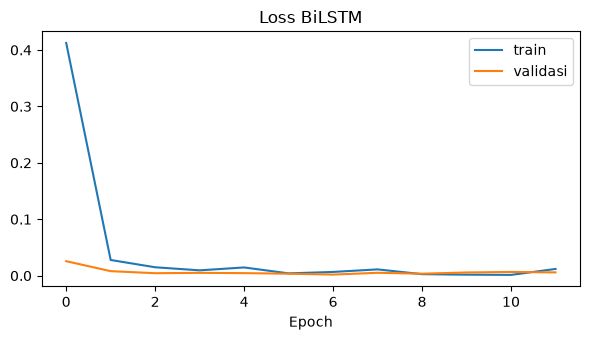

In [65]:
plt.figure(figsize=(6, 3.5))
plt.plot(history_bil.history['loss'], label='train')
plt.plot(history_bil.history['val_loss'], label='validasi')
plt.title('Loss BiLSTM')
plt.xlabel('Epoch')
plt.legend() 
plt.tight_layout()
plt.show()

## Skema 3 — CNN | Tokenizer + Padding (Embedding)

In [66]:
MAX_WORDS, MAX_LEN = 3000, 20

tokenizer_cnn = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer_cnn.fit_on_texts(X_tr)

X_tr_seq_cnn = to_seq(tokenizer_cnn, X_tr)
X_val_seq_cnn = to_seq(tokenizer_cnn, X_val)
X_train_seq_cnn = to_seq(tokenizer_cnn, X_train)
X_test_seq_cnn = to_seq(tokenizer_cnn, X_test)

model_cnn = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(len(tokenizer_cnn.word_index) + 1, 128),
        layers.Conv1D(128, 3, activation='relu'),
        layers.GlobalMaxPooling1D(),
        layers.Dropout(0.5),
        layers.Dense(64, activation='relu'),
        layers.Dense(len(le.classes_), activation='softmax')
])
model_cnn.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

early_stop = callbacks.EarlyStopping(monitor='val_loss', 
                                     patience=5, 
                                     restore_best_weights=True)

history_cnn = model_cnn.fit(
    X_tr_seq_cnn, y_tr,
    validation_split=0.1,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=2
)

y_pred_train_cnn = model_cnn.predict(X_train_seq_cnn, verbose=0).argmax(axis=1)
y_pred_test_cnn = model_cnn.predict(X_test_seq_cnn, verbose=0).argmax(axis=1)
 
accuracy_train_cnn = accuracy_score(y_train_enc, y_pred_train_cnn)
accuracy_test_cnn = accuracy_score(y_test_enc, y_pred_test_cnn)
f1_test_cnn = f1_score(y_test_enc, y_pred_test_cnn, average='macro')
 
print('CNN - accuracy_train:', accuracy_train_cnn)
print('CNN - accuracy_test:', accuracy_test_cnn)
print('CNN - macro_f1_test:', f1_test_cnn)

Epoch 1/50
608/608 - 10s - 17ms/step - accuracy: 0.8562 - loss: 0.4923 - val_accuracy: 0.9991 - val_loss: 0.0046
Epoch 2/50
608/608 - 7s - 11ms/step - accuracy: 0.9977 - loss: 0.0110 - val_accuracy: 0.9991 - val_loss: 0.0030
Epoch 3/50
608/608 - 6s - 10ms/step - accuracy: 0.9996 - loss: 0.0036 - val_accuracy: 0.9995 - val_loss: 8.6172e-04
Epoch 4/50
608/608 - 10s - 17ms/step - accuracy: 0.9996 - loss: 0.0022 - val_accuracy: 0.9991 - val_loss: 0.0040
Epoch 5/50
608/608 - 7s - 11ms/step - accuracy: 0.9995 - loss: 0.0020 - val_accuracy: 0.9995 - val_loss: 0.0025
Epoch 6/50
608/608 - 11s - 17ms/step - accuracy: 0.9997 - loss: 0.0014 - val_accuracy: 0.9991 - val_loss: 0.0037
Epoch 7/50
608/608 - 8s - 13ms/step - accuracy: 0.9993 - loss: 0.0026 - val_accuracy: 0.9995 - val_loss: 7.3708e-04
Epoch 8/50
608/608 - 9s - 15ms/step - accuracy: 0.9997 - loss: 0.0011 - val_accuracy: 0.9995 - val_loss: 0.0024
Epoch 9/50
608/608 - 11s - 18ms/step - accuracy: 0.9996 - loss: 0.0012 - val_accuracy: 0.9991

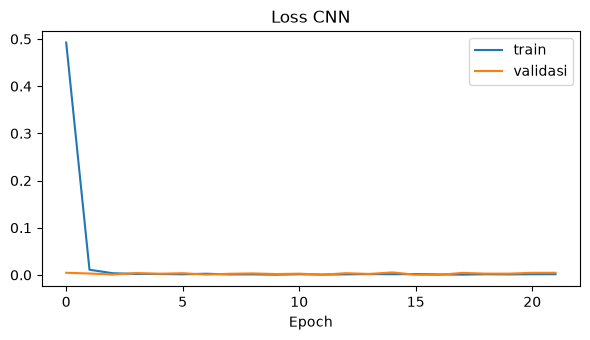

In [67]:
plt.figure(figsize=(6, 3.5))
plt.plot(history_cnn.history['loss'], label='train')
plt.plot(history_cnn.history['val_loss'], label='validasi')
plt.title('Loss CNN')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.show()

## Ringkasan Hasil dari Ketiga Skema

In [68]:
prediksi_test = {
    'Logistic Regression (TF-IDF)': y_pred_test_lr,
    'BiLSTM': y_pred_test_bil,
    'CNN': y_pred_test_cnn,
}
prediksi_train = {
    'Logistic Regression (TF-IDF)': y_pred_train_lr,
    'BiLSTM': y_pred_train_bil,
    'CNN': y_pred_train_cnn,
}

def akurasi_per_bahasa(y_true, y_pred):
    return {b: accuracy_score(y_true[bahasa_test == b], y_pred[bahasa_test == b])
            for b in sorted(set(bahasa_test))}

baris = []
for nama in prediksi_test:
    akurasi_bahasa = akurasi_per_bahasa(y_test_enc, prediksi_test[nama])
    baris.append({
        'Model': nama,
        'Akurasi Train': accuracy_score(y_train_enc, prediksi_train[nama]),
        'Akurasi Test': accuracy_score(y_test_enc, prediksi_test[nama]),
        'Macro F1': f1_score(y_test_enc, prediksi_test[nama], average='macro'),
        'Weighted F1': f1_score(y_test_enc, prediksi_test[nama], average='weighted'),
        'Akurasi Indonesia': akurasi_bahasa['Indonesia'],
        'Akurasi Sunda': akurasi_bahasa['Sunda'],
    })

hasil_df = pd.DataFrame(baris)

KOMPLEKSITAS = {'Logistic Regression (TF-IDF)': 1, 'CNN': 2, 'BiLSTM': 3}
hasil_df['Kompleksitas'] = hasil_df['Model'].map(KOMPLEKSITAS)
hasil_df = hasil_df.sort_values(['Macro F1', 'Kompleksitas'],
                                ascending=[False, True]).reset_index(drop=True)

display(hasil_df.drop(columns='Kompleksitas').round(4))

selisih = hasil_df['Macro F1'].max() - hasil_df['Macro F1'].min()
print(f'Selisih macro-F1 tertinggi vs terendah: {selisih:.4f}')
if selisih < 0.01:
    print('Semua model praktis setara; urutan pemilihan memakai model paling sederhana.')

,Model,Akurasi Train,Akurasi Test,Macro F1,Weighted F1,Akurasi Indonesia,Akurasi Sunda
0,Logistic Regression (TF-IDF),1.0000,0.9995,0.9995,0.9995,0.9995,0.9995
1,CNN,0.9999,0.9992,0.9992,0.9992,0.9995,1.0000
2,BiLSTM,0.9995,0.9985,0.9985,0.9985,0.9975,0.9995


Selisih macro-F1 tertinggi vs terendah: 0.0010
Semua model praktis setara; urutan pemilihan memakai model paling sederhana.


In [69]:
nama_terbaik = hasil_df.loc[0, 'Model']
print('Model terpilih:', nama_terbaik)

def proba_lr(teks):
    return lr.predict_proba(tfidf.transform(list(teks)))

def proba_bilstm(teks):
    return model_bil.predict(to_seq(tokenizer_bil, teks), verbose=0)

def proba_cnn(teks):
    return model_cnn.predict(to_seq(tokenizer_cnn, teks), verbose=0)

PROBA = {
    'Logistic Regression (TF-IDF)': proba_lr,
    'BiLSTM': proba_bilstm,
    'CNN': proba_cnn,
}
proba_terbaik = PROBA[nama_terbaik]

p_test = proba_terbaik(X_test)
y_pred_terbaik = p_test.argmax(axis=1)
confidence_test = p_test.max(axis=1)

print(classification_report(y_test_enc, y_pred_terbaik,
                            target_names=le.classes_, digits=3, zero_division=0))

ringkas_bahasa = []
for b in sorted(set(bahasa_test)):
    mask = bahasa_test == b
    ringkas_bahasa.append({
        'Bahasa': b,
        'Jumlah': int(mask.sum()),
        'Akurasi': accuracy_score(y_test_enc[mask], y_pred_terbaik[mask]),
        'Macro F1': f1_score(y_test_enc[mask], y_pred_terbaik[mask], average='macro'),
    })
display(pd.DataFrame(ringkas_bahasa).round(4))

Model terpilih: Logistic Regression (TF-IDF)
                   precision    recall  f1-score   support

  cek_jatuh_tempo      0.999     1.000     0.999       667
         cek_unit      0.999     0.999     0.999       667
      info_kontak      1.000     0.999     0.999       667
      info_lokasi      1.000     1.000     1.000       667
          keluhan      1.000     1.000     1.000       667
          lainnya      1.000     1.000     1.000       666
status_pembayaran      1.000     1.000     1.000       666
     tanya_aturan      1.000     0.998     0.999       666
  tanya_fasilitas      0.999     1.000     0.999       667

         accuracy                          1.000      6000
        macro avg      1.000     0.999     1.000      6000
     weighted avg      1.000     1.000     0.999      6000



,Bahasa,Jumlah,Akurasi,Macro F1
0,Campuran,1986,0.9995,0.9995
1,Indonesia,1987,0.9995,0.9995
2,Sunda,2027,0.9995,0.9995


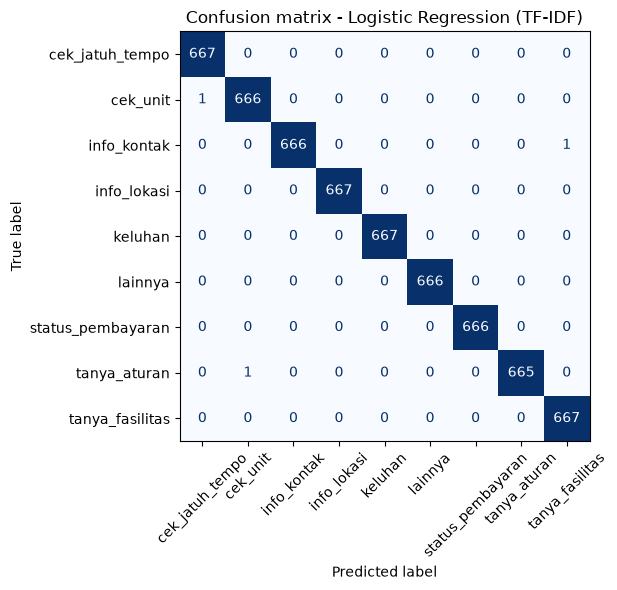

In [70]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_enc, y_pred_terbaik, display_labels=le.classes_,
    xticks_rotation=45, cmap='Blues', colorbar=False, ax=ax,
)
plt.title('Confusion matrix - ' + nama_terbaik)
plt.tight_layout()
plt.show()

In [71]:
salah = pd.DataFrame({
    'teks': test_df['text'].to_numpy(),
    'bahasa': bahasa_test,
    'benar': le.inverse_transform(y_test_enc),
    'prediksi': le.inverse_transform(y_pred_terbaik),
    'confidence': confidence_test.round(3),
})
salah = salah[salah['benar'] != salah['prediksi']]
print('Salah prediksi:', len(salah), 'dari', len(y_test_enc))
display(salah.sort_values('confidence', ascending=False).head(15).reset_index(drop=True))

Salah prediksi: 3 dari 6000


,teks,bahasa,benar,prediksi,confidence
0,"halo kang, abdi panghuni kamar B4, bs msaak di...",Campuran,tanya_aturan,cek_unit,0.822
1,"punten ngaganggu hiji deui, kamar koosng kantu...",Sunda,cek_unit,cek_jatuh_tempo,0.531
2,hai kak eamil penjaga kosan brp ya buat pegang...,Indonesia,info_kontak,tanya_fasilitas,0.397


In [72]:
idx_lainnya = int(np.where(le.classes_ == 'lainnya')[0][0])

baris = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    diterima = confidence_test >= t
    final = np.where(diterima, y_pred_terbaik, idx_lainnya)
    baris.append({
        'Threshold': t,
        'Cakupan': diterima.mean(),
        'Akurasi (diterima)': accuracy_score(y_test_enc[diterima], y_pred_terbaik[diterima]),
        'Macro F1 (dengan fallback)': f1_score(y_test_enc, final, average='macro'),
    })

tabel_threshold = pd.DataFrame(baris)
print('Macro F1 tanpa fallback:', round(f1_score(y_test_enc, y_pred_terbaik, average='macro'), 4))
display(tabel_threshold.round(4))

Macro F1 tanpa fallback: 0.9995


,Threshold,Cakupan,Akurasi (diterima),Macro F1 (dengan fallback)
0,0.3,1.0000,0.9995,0.9995
1,0.4,0.9998,0.9997,0.9995
2,0.5,0.9998,0.9997,0.9995
3,0.6,0.9995,0.9998,0.9993
4,0.7,0.9988,0.9998,0.9987
5,0.8,0.9960,0.9998,0.9959
6,0.9,0.9868,1.0000,0.9879


In [74]:
ARTIFACT_DIR = Path('artifacts/intent')
THRESHOLD = 0.5

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(tfidf, ARTIFACT_DIR / 'tfidf_vectorizer.joblib')
joblib.dump(lr, ARTIFACT_DIR / 'logreg.joblib')
joblib.dump(le, ARTIFACT_DIR / 'label_encoder.joblib')

(ARTIFACT_DIR / 'tokenizer_bilstm.json').write_text(tokenizer_bil.to_json(), encoding='utf-8')
(ARTIFACT_DIR / 'tokenizer_cnn.json').write_text(tokenizer_cnn.to_json(), encoding='utf-8')
model_bil.save(ARTIFACT_DIR / 'model_bilstm.keras')
model_cnn.save(ARTIFACT_DIR / 'model_cnn.keras')

config = {
    'model_terbaik': nama_terbaik,
    'classes': list(le.classes_),
    'max_words': MAX_WORDS,
    'max_len': MAX_LEN,
    'threshold': THRESHOLD,
    'seed': SEED,
}
(ARTIFACT_DIR / 'config.json').write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8')
hasil_df.to_csv(ARTIFACT_DIR / 'hasil_perbandingan.csv', index=False)

print('Artefak tersimpan di:', ARTIFACT_DIR.resolve())
print(sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Artefak tersimpan di: D:\Kuliah\SEMESTER 5\ASAH\Kontrakan\ml-training\artifacts\intent
['config.json', 'hasil_perbandingan.csv', 'label_encoder.joblib', 'logreg.joblib', 'model_bilstm.keras', 'model_cnn.keras', 'tfidf_vectorizer.joblib', 'tokenizer_bilstm.json', 'tokenizer_cnn.json']
